<h2 style="font-weight:600;color:#4f7a9b">K-Means Clustering on the Handwritten Digits Data</h2>

We'll compare the various **initialization strategies** for K-means, in terms of:
- runtime
- quality of the results

Start by loading a dataset of handwritten digits from 0 to 9. Each digit is represented by an 8x8 image.

<h3 style="font-weight:600;color:#4f7a9b">Load the Dataset</h3>

In [4]:
import numpy as np
from sklearn.datasets import load_digits

data, labels = load_digits(return_X_y=True)
n_samples, n_features = data.shape
n_digits = np.unique(labels).size

print(f"# digits: {n_digits}; # samples {n_samples}; # features {n_features}")

# digits: 10; # samples 1797; # features 64


There are 1,797 samples, where each sample has 64 features (a 8x8 image) and there are a total of 10 digits (0, 1, ...9)

<h3 style="font-weight:600;color:#4f7a9b">Define our Evaluation Benchmark</h3>

In [ ]:
from time import time
import matplotlib.pyplot as plt

from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay


def bench_k_means(kmeans: KMeans, name: str, data: np.ndarray, labels: np.ndarray):
    """
    Benchmark to evaluate the KMeans initialization methods.

    Parameters
    ----------
    kmeans : KMeans instance
        A class: `sklearn.cluster.KMeans` instance with the initialization already set.
    name : str
        Name given to the strategy. It will be used to show the results in a table.
    data : ndarray of shape (n_samples, n_features)
        The data to cluster.
    labels : ndarray of shape (n_samples,)
        The labels used to compute the clustering metrics which requires some supervision.
    """
    t0 = time()

    estimator = make_pipeline(StandardScaler(), kmeans).fit(data)

    fit_time = time() - t0

    results = [name, fit_time, estimator[-1].inertia_]

    # Define the metrics which require only the true labels and estimator labels.
    clustering_metrics = [
        metrics.homogeneity_score,
        metrics.completeness_score,
        metrics.v_measure_score,
        metrics.adjusted_rand_score,
        metrics.adjusted_mutual_info_score,
    ]

    results += [m(labels, estimator[-1].labels_) for m in clustering_metrics]

    # The silhouette score requires the full dataset
    results += [
        metrics.silhouette_score(
            data,
            estimator[-1].labels_,
            metric="euclidean",
            sample_size=300,
        )
    ]

    # Show the results
    formatter_result = "{:9s}\t{:.3f}s\t{:.0f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}"
    print(formatter_result.format(*results))

<h3 style="font-weight:600;color:#4f7a9b">Run the Benchmark</h3>

In [20]:
print(82 * "_")
print("init\t\ttime\tinertia\thomo\tcompl\tv-meas\tARI\tAMI\tsilhouette")

kmeans = KMeans(n_clusters=n_digits, init="k-means++", n_init=4, random_state=0)
bench_k_means(kmeans, "k-means++", data, labels)

kmeans = KMeans(n_clusters=n_digits, init="random", n_init=4, random_state=0)
bench_k_means(kmeans, "random", data, labels)

pca = PCA(n_components=n_digits).fit(data)
kmeans = KMeans(n_clusters=n_digits, init=pca.components_, n_init=1)
bench_k_means(kmeans, "PCA-based", data, labels)

print(82 * "_")

__________________________________________________________________________________
init		time	inertia	homo	compl	v-meas	ARI	AMI	silhouette
k-means++	0.097s	69545	0.598	0.645	0.621	0.469	0.617	0.146
random   	0.050s	69735	0.681	0.723	0.701	0.574	0.698	0.175
PCA-based	0.008s	69513	0.600	0.647	0.622	0.468	0.618	0.163
__________________________________________________________________________________


<h3 style="font-weight:600;color:#4f7a9b">Visualize the results on PCA-reduced data</h3>

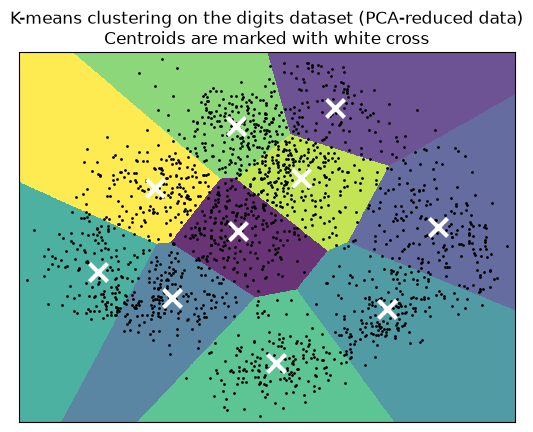

In [26]:
reduced_data = PCA(n_components=2).fit_transform(data)
kmeans = KMeans(n_clusters=n_digits, init="k-means++", n_init=4, random_state=42)
kmeans.fit(reduced_data)

plt.figure()

DecisionBoundaryDisplay.from_estimator(
    kmeans,
    reduced_data,
    ax=plt.gca(),
    response_method="predict",
    alpha=0.8,
    plot_method="pcolormesh",
    grid_resolution=1000,
)

plt.plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)

# Plot the centroids as a white X.
centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="x",
    s=169,
    linewidths=3,
    color="w",
    zorder=10,
)

plt.title("K-means clustering on the digits dataset (PCA-reduced data)\n" "Centroids are marked with white cross")
plt.xticks(())
plt.yticks(())
plt.show()